# MGS-07f : Redémarrages à population croissante — ce que l'IPOP change sur un paysage multimodal

MGS-07e CMA-ES · [MGS-07d MichalewiczDixonPrice](MGS-07d-MichalewiczDixonPrice.ipynb) · [MGS-08 LandscapeExplorer →](MGS-08-LandscapeExplorer.ipynb)

MGS-07e a mesuré ce que l'adaptation de covariance achète sur une **vallée orientée** — un paysage unimodal où toute la difficulté est géométrique. Il a aussi rencontré le plafond du composé : la stratégie redémarre toute seule quand elle stagne, mais la population ne change pas. L'exercice 1 faisait construire la boucle de doublement **côté appelant**.

Ce carnet reprend exactement là : la boucle existe désormais dans la librairie — `IpopRestartController` (sous-module, livraison du 17/11) — et nous la branchons sur le même canevas GA. La question devient mesurable :

> À **budget d'évaluations égal**, doubler la population à chaque redémarrage améliore-t-il l'atteinte de l'optimum global sur un paysage multimodal ?

La réponse courte d'Auger et Hansen (CEC 2005) : oui, massivement — sur la suite CEC 2005, l'IPOP bat le redémarrage local à population constante dans 29 des 60 cas multimodaux testés, et en perd 4 ; sur les unimodaux, les deux se valent. Ce carnet mesure ces trois régimes (deux multimodaux, un unimodal) à notre échelle, avec le vrai moteur.


In [1]:
// References : les quatre DLL du domaine MetaGeneticSharp compilees en Release —
// GeneticSharp.Infrastructure.Framework (socle commun du moteur), GeneticSharp.Domain
// (algorithme genetique de base), MetaGeneticSharp.Infrastructure (utilitaires propres),
// MetaGeneticSharp.Domain (metaheuristiques geometriques, dont IpopRestartController).
// Le carnet branche le moteur local du depot, pas un paquet NuGet.
#r "../MetaGeneticSharp/src/MetaGeneticSharp.Domain/bin/Release/net9.0/GeneticSharp.Infrastructure.Framework.dll"
#r "../MetaGeneticSharp/src/MetaGeneticSharp.Domain/bin/Release/net9.0/GeneticSharp.Domain.dll"
#r "../MetaGeneticSharp/src/MetaGeneticSharp.Domain/bin/Release/net9.0/MetaGeneticSharp.Infrastructure.dll"
#r "../MetaGeneticSharp/src/MetaGeneticSharp.Domain/bin/Release/net9.0/MetaGeneticSharp.Domain.dll"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Text;
using System.Globalization;
using GeneticSharp;
using MetaGeneticSharp;
using C = MetaGeneticSharp.CovarianceMatrixAdaptationEvolutionStrategyMath;
Console.WriteLine($"MetaGeneticSharp {typeof(IpopRestartController).Assembly.GetName().Version}, GeneticSharp {typeof(GeneticSharp.IRandomization).Assembly.GetName().Version}");
Console.WriteLine($"IpopRestartController present : {typeof(IpopRestartController).Name}");


MetaGeneticSharp 1.0.0.0, GeneticSharp 3.1.4.0


IpopRestartController present : IpopRestartController


## L'organe : `IpopRestartController`

La classe coordonne des exécutions CMA-ES **indépendantes** en doublant la population à chaque redémarrage. Son contrat est volontairement mince — tout ce qui est spécifique au problème reste à la charge de l'appelant :

| Ce que le contrôleur fait | Ce qu'il laisse à l'appelant |
|---|---|
| double la population à chaque restart (`checked`, débordement surveillé) | construire le GA de chaque exécution (callback `run(size, restart)`)|
| conserver le meilleur résultat en **maximisation** | les critères d'arrêt de chaque exécution |
| arrêter dès qu'un callback déclare `Stop` (cible atteinte, etc.) | le **budget global** d'évaluations |
| rendre la trace `PopulationSizes` réellement exécutées | la fitness et le domaine |

```csharp
IpopResult<T> Run<T>(int initialPopulationSize, int maxRestarts,
                     Func<int, int, IpopRunResult<T>> run)
// IpopRunResult<T>(T Value, double Fitness, bool Stop)
// IpopResult<T>(T Value, double Fitness, IReadOnlyList<int> PopulationSizes, bool Stopped)
```

Le premier geste du carnet est le même que celui du test d'intégration de la librairie : vérifier sur un problème-jouet que l'orchestration fait bien ce que son contrat dit — populations observées 4, 8, 16, arrêt propre.


In [2]:
// Le chromosome du run de controle : transcription verbatim de la classe privee du test
// (elle vit dans le fichier de test, pas dans la librairie).
/// <summary>A chromosome that randomises each gene in [min, max] on CreateNew, so the initial population is diverse.</summary>
sealed class RandomDoubleChromosomeCtl : ChromosomeBase
{
    private readonly double _min;
    private readonly double _max;

    public RandomDoubleChromosomeCtl(double min, double max, int length) : base(length)
    {
        _min = min;
        _max = max;
        var rnd = RandomizationProvider.Current;
        for (int i = 0; i < Length; i++)
            ReplaceGene(i, new Gene(_min + rnd.GetDouble() * (_max - _min)));
    }

    public override IChromosome CreateNew() => new RandomDoubleChromosomeCtl(_min, _max, Length);

    public override Gene GenerateGene(int geneIndex) =>
        new Gene(_min + RandomizationProvider.Current.GetDouble() * (_max - _min));

    public double[] GetDoubleValues() => GetGenes().Select(g => (double)g.Value).ToArray();
}
Console.WriteLine("chromosome de controle defini");


chromosome de controle defini


In [3]:
// Run de controle : transcription du test d'integration Run_ExecutesIndependentCmaEsPopulations.
// Sphere 2-D, 5 generations par execution, populations attendues 4 -> 8 -> 16.
var observed = new List<int>();
var ctl = IpopRestartController.Run(4, 2, (size, restart) =>
{
    var strategy = new CovarianceMatrixAdaptationEvolutionStrategy { MaxGenerations = 5 };
    strategy.SetGeometricConverter(new GeometricConverter<double>
    {
        GeneToDoubleConverter = (_, value) => value,
        DoubleToGeneConverter = (_, value) => value,
    });
    var chromosome = new RandomDoubleChromosomeCtl(min: -10, max: 10, length: 2);
    var population = new MetaPopulation(size, size, chromosome);
    var fitness = new FuncFitness(c => -((RandomDoubleChromosomeCtl)c).GetDoubleValues().Sum(x => x * x));
    var ga = new MetaGeneticAlgorithm(population, fitness, new EliteSelection(),
        new UniformCrossover(0.5f), new UniformMutation(true), strategy.Build())
    {
        Termination = new GenerationNumberTermination(5)
    };
    ga.Start();
    observed.Add(population.CurrentGeneration.Chromosomes.Count);
    return new IpopRunResult<IChromosome>(ga.BestChromosome, ga.BestChromosome.Fitness!.Value, false);
});
Console.WriteLine($"populations observees : {string.Join(" -> ", observed)}");
Console.WriteLine($"PopulationSizes rendues : {string.Join(", ", ctl.PopulationSizes)} ;Stopped = {ctl.Stopped} ; meilleur fitness = {ctl.Fitness:F3}");


populations observees : 4 -> 8 -> 16


PopulationSizes rendues : 4, 8, 16 ;Stopped = False ; meilleur fitness = -0,023


## Trois paysages, deux régimes

Le protocole d'Auger et Hansen compare l'IPOP au **redémarrage local** — même mécanisme de restart, population **constante**. Nous reproduisons cette paire sur trois paysages 5-D, chacun illustrant un régime du verdict du papier :

| Paysage | Régime | Domaine canonique | Ce qu'on attend (papier, CEC 2005) |
|---|---|---|---|
| **Rastrigin d=5** | multimodal sévère (≈ 101 minima locaux en 5-D) | $[-5{,}12, 5{,}12]^5$ | l'IPOP doit dominer : chaque restart plus global escape différemment |
| **Ackley d=5** | multimodal régulier, vallée large à fond presque plat | $[-32{,}768, 32{,}768]^5$ | même régime, courbe différente |
| **Sphere d=5** | unimodal | $[-10, 10]^5$ | « performance is similar » : la première exécution converge, les restarts ne servent à rien |

Le troisième cas est aussi important que les deux premiers : c'est le **négatif honnête**. Une stratégie de restart qui « gagne » partout serait suspecte ; le papier en perd 4 cas sur 60 — nous mesurons le nôtre.


In [4]:
// Les trois paysages 5-D, definitions canoniques.
double Rastrigin(double[] x)
{
    double s = 10.0 * x.Length;
    foreach (double xi in x) s += xi * xi - 10.0 * Math.Cos(2.0 * Math.PI * xi);
    return s;
}
double Ackley(double[] x)
{
    int n = x.Length;
    double a = 20.0, b = 0.2, c = 2.0 * Math.PI;
    double sum1 = 0, sum2 = 0;
    foreach (double xi in x) { sum1 += xi * xi; sum2 += Math.Cos(c * xi); }
    return -a * Math.Exp(-b * Math.Sqrt(sum1 / n)) - Math.Exp(sum2 / n) + a + Math.E;
}
double Sphere(double[] x)
{
    double s = 0;
    foreach (double xi in x) s += xi * xi;
    return s;
}
var Landscapes = new (string Name, Func<double[], double> F, double Min, double Max)[]
{
    ("Rastrigin d=5", Rastrigin, -5.12, 5.12),
    ("Ackley d=5",    Ackley,   -32.768, 32.768),
    ("Sphere d=5",    Sphere,   -10.0, 10.0),
};
foreach (var (name, f, lo, hi) in Landscapes)
{
    double at0 = f(new double[5]);
    double atCorner = f(Enumerable.Repeat(hi, 5).ToArray());
    Console.WriteLine($"{name,-14} domaine [{lo}, {hi}]^5 ; f(0) = {at0:F2} ; f(coin) = {atCorner:F2}");
}


Rastrigin d=5  domaine [-5,12, 5,12]^5 ; f(0) = 0,00 ; f(coin) = 144,62


Ackley d=5     domaine [-32,768, 32,768]^5 ; f(0) = 0,00 ; f(coin) = 21,57


Sphere d=5     domaine [-10, 10]^5 ; f(0) = 0,00 ; f(coin) = 500,00


## Le canevas : une exécution, une population — le budget chez l'appelant

Chaque exécution individuelle est le canevas de MGS-07e : chromosome aléatoire dans le domaine, CMA-ES branché sur le moteur GA, comptage des évaluations par le `FuncFitness`. Ce qui change : la population de l'exécution est **un paramètre**, et deux harnais l'entourent.

- **`RunIpop`** passe par `IpopRestartController` : le contrôleur choisit les tailles (doublées), le callback rend `Stop` dès que la cible $10^{-8}$ est atteinte ou le budget épuisé — c'est la garde de budget « côté appelant » que le contrat du contrôleur laisse ouverte, exactement le complément déclaré manquant de l'API.
- **`RunFixed`** est le miroir du redémarrage local du papier : même boucle, même budget, même cible — la population ne change jamais.
- **Fin d'un run individuel : la stagnation, pas un cap de générations.** Un run s'arrête quand son meilleur n'a pas progressé pendant 25 générations (l'analogue du `tolstagnation` du CMA-ES), avec un filet de 400 générations. Un cap commun de générations affamerait le redémarrage local — ses runs à population constante consommeraient une fraction du budget sans jamais avoir le temps de raffiner — et fausserait la comparaison à budget égal.

Même graine par run : les deux stratégies voient la même séquence aléatoire initiale, seules divergent les tailles de population au fil des restarts.

In [5]:
// Le chromosome du banc (transcription verbatim, cf. cellule de controle pour la provenance).
/// <summary>A chromosome that randomises each gene in [min, max] on CreateNew, so the initial population is diverse.</summary>
sealed class RandomDoubleChromosome : ChromosomeBase
{
    private readonly double _min;
    private readonly double _max;

    public RandomDoubleChromosome(double min, double max, int length) : base(length)
    {
        _min = min;
        _max = max;
        var rnd = RandomizationProvider.Current;
        for (int i = 0; i < Length; i++)
            ReplaceGene(i, new Gene(_min + rnd.GetDouble() * (_max - _min)));
    }

    public override IChromosome CreateNew() => new RandomDoubleChromosome(_min, _max, Length);

    public override Gene GenerateGene(int geneIndex) =>
        new Gene(_min + RandomizationProvider.Current.GetDouble() * (_max - _min));

    public double[] GetDoubleValues() => GetGenes().Select(g => (double)g.Value).ToArray();
}

record StratOutcome(int Evals, double Best, int ReachedAt, IReadOnlyList<int> Sizes, List<(int Evals, double Best)> Trace);

// Compteur mutable partage entre le harnais et les lambdas du moteur : un parametre `ref`
// ne peut pas etre capture par une lambda (CS1628), une classe le peut.
sealed class RunLedger
{
    public int TotalEvals;
    public double Best = double.PositiveInfinity;
    public int ReachedAt = -1; // evals cumules au premier passage sous la cible, -1 si jamais
}

// Une execution CMA-ES a population donnee, instrumentee : compteur d'evals, meilleur global
// et passage sous cible portes par le ledger ; la trace enregistre (evals, meilleur) par generation.
// Fin de run : stagnation (stallGens generations sans amelioration du meilleur du run — l'analogue
// du tolstagnation du CMA-ES) avec filet maxGens, pour que chaque harnais consomme reellement
// son budget global au lieu d'arreter ses runs sur un cap commun de generations.
void OneRun(
    Func<double[], double> f, double lo, double hi, int size, int stallGens, int maxGens,
    RunLedger ledger, double target, List<(int, double)> trace)
{
    var strategy = new CovarianceMatrixAdaptationEvolutionStrategy();
    strategy.SetGeometricConverter(new GeometricConverter<double>
    {
        GeneToDoubleConverter = (_, v) => v,
        DoubleToGeneConverter = (_, d) => d,
    });
    var chromosome = new RandomDoubleChromosome(lo, hi, 5);
    var fitness = new FuncFitness(c =>
    {
        ledger.TotalEvals++;
        double fv = f(((RandomDoubleChromosome)c).GetDoubleValues());
        if (fv < ledger.Best)
        {
            ledger.Best = fv;
            if (fv <= target && ledger.ReachedAt < 0) ledger.ReachedAt = ledger.TotalEvals;
        }
        return -fv;
    });
    var population = new MetaPopulation(size, size, chromosome);
    var ga = new MetaGeneticAlgorithm(population, fitness, new EliteSelection(),
        new UniformCrossover(0.5f), new UniformMutation(true), strategy.Build())
    {
        Termination = new OrTermination(
            new FitnessStagnationTermination(stallGens),
            new GenerationNumberTermination(maxGens))
    };
    ga.GenerationRan += (_, _) => trace.Add((ledger.TotalEvals, ledger.Best));
    ga.Start();
}

// Harnais IPOP : le controleur orchestre, la garde de budget vit dans le callback (cote appelant).
StratOutcome RunIpop(Func<double[], double> f, double lo, double hi, int seed,
    int lambda0, int maxRestarts, int budget, double target = 1e-8, int stallPerRun = 25, int maxGensPerRun = 400)
{
    BasicRandomization.ResetSeed(seed);
    var previous = RandomizationProvider.Current;
    RandomizationProvider.Current = new BasicRandomization();
    try
    {
        var ledger = new RunLedger();
        var trace = new List<(int, double)>();
        var res = IpopRestartController.Run(lambda0, maxRestarts, (size, restart) =>
        {
            int gens = Math.Min(maxGensPerRun, Math.Max(1, (budget - ledger.TotalEvals) / size));
            OneRun(f, lo, hi, size, stallPerRun, gens, ledger, target, trace);
            bool stop = ledger.ReachedAt > 0 || ledger.TotalEvals >= budget;
            return new IpopRunResult<IChromosome>(null, -ledger.Best, stop);
        });
        return new StratOutcome(ledger.TotalEvals, ledger.Best, ledger.ReachedAt, res.PopulationSizes, trace);
    }
    finally
    {
        RandomizationProvider.Current = previous;
    }
}

// Harnais redemarrage local : population constante, meme budget, meme cible — le miroir du papier.
StratOutcome RunFixed(Func<double[], double> f, double lo, double hi, int seed,
    int lambda0, int maxRestarts, int budget, double target = 1e-8, int stallPerRun = 25, int maxGensPerRun = 400)
{
    BasicRandomization.ResetSeed(seed);
    var previous = RandomizationProvider.Current;
    RandomizationProvider.Current = new BasicRandomization();
    try
    {
        var ledger = new RunLedger();
        var trace = new List<(int, double)>();
        var sizes = new List<int>();
        for (int restart = 0; restart <= maxRestarts; restart++)
        {
            int gens = Math.Min(maxGensPerRun, Math.Max(1, (budget - ledger.TotalEvals) / lambda0));
            OneRun(f, lo, hi, lambda0, stallPerRun, gens, ledger, target, trace);
            sizes.Add(lambda0);
            if (ledger.ReachedAt > 0 || ledger.TotalEvals >= budget) break;
        }
        return new StratOutcome(ledger.TotalEvals, ledger.Best, ledger.ReachedAt, sizes, trace);
    }
    finally
    {
        RandomizationProvider.Current = previous;
    }
}

// Passe de reference : Sphere, graine 4242 — un paysage facile doit converger au premier run,
// sans que le controleur ait besoin de doubler la population.
var sanity = RunIpop(Sphere, -10.0, 10.0, 4242, lambda0: 8, maxRestarts: 6, budget: 50_000);
Console.WriteLine($"IPOP/Sphere graine 4242 : {sanity.Evals} evals, meilleur f = {sanity.Best:E3}, cible a {(sanity.ReachedAt > 0 ? sanity.ReachedAt.ToString() : "jamais")}, tailles [{string.Join(",", sanity.Sizes)}]");

IPOP/Sphere graine 4242 : 3200 evals, meilleur f = 2,529E-037, cible a 862, tailles [8]


## Le protocole : budget égal, mesure au premier passage sous la cible

Le protocole suit le papier sur les trois points qui rendent la comparaison loyale :

1. **Budget global identique et réellement consommé** pour les deux stratégies : $n \times 10^4 = 50\\,000$ évaluations en d=5 — chaque run s'arrête sur stagnation (25 générations sans amélioration), le nombre de restarts n'est qu'un filet, et la colonne « évals consommées » du banc atteste que ni l'une ni l'autre ne rend son budget.
2. **Cible unique** : erreur $f(x) - f(x^\\ast) \\le 10^{-8}$, comptée à l'évaluation où le meilleur courant passe sous la cible pour la première fois.
3. **Population initiale papier** : $\\lambda(5) = 4 + \\lfloor 3\\ln 5 \\rfloor = 8$ — l'IPOP la double à chaque restart, le redémarrage local la garde.

Trois graines {4242, 1717, 2718} par cellule du tableau, comme MGS-07e.

In [6]:
// Le banc : 2 strategies x 3 paysages x 3 graines, budget 50 000 evals, cible 1e-8.
// MaxRestarts = filet haut : l'arret reel de chaque strategie est le budget ou la cible
// (le protocole du papier — le nombre de restarts n'est pas le facteur limitant).
int[] Seeds = { 4242, 1717, 2718 };
int Budget = 50_000, Lambda0 = 8, MaxRestarts = 200;
string SizesTxt(IReadOnlyList<int> s) =>
    s.Count <= 12 ? string.Join(",", s) : $"{s[0]} x{s.Count} runs";
var results = new Dictionary<string, List<StratOutcome>>();
foreach (var (name, f, lo, hi) in Landscapes)
{
    foreach (var (strat, run) in new (string, Func<Func<double[], double>, double, double, int, StratOutcome>)[]
    {
        ("IPOP",  (fn, a, b, s) => RunIpop(fn, a, b, s, Lambda0, MaxRestarts, Budget)),
        ("fixe",  (fn, a, b, s) => RunFixed(fn, a, b, s, Lambda0, MaxRestarts, Budget)),
    })
    {
        var key = $"{name}|{strat}";
        var runs = new List<StratOutcome>();
        foreach (int seed in Seeds) runs.Add(run(f, lo, hi, seed));
        results[key] = runs;
        int reached = runs.Count(r => r.ReachedAt > 0);
        var reachedEvals = runs.Where(r => r.ReachedAt > 0).Select(r => (double)r.ReachedAt).DefaultIfEmpty(-1).OrderBy(e => e).ToList();
        double med = reachedEvals.Count > 0 && reachedEvals[0] > 0 ? reachedEvals[(reached - 1) / 2] : -1;
        var medRun = runs.OrderBy(r => r.Best).ElementAt(runs.Count / 2);
        Console.WriteLine($"{name,-14} {strat,-4} | {reached}/3 atteignent 1e-8 | mediane meilleur f = {medRun.Best,10:E3} | evals medianes = {(med > 0 ? ((int)med).ToString() : "jamais")} | mediane evals consommees = {runs.OrderBy(r => r.Evals).ElementAt(1).Evals} | tailles medianes [{SizesTxt(medRun.Sizes)}]");
    }
}

Rastrigin d=5  IPOP | 3/3 atteignent 1e-8 | mediane meilleur f = 0,000E+000 | evals medianes = 22065 | mediane evals consommees = 27688 | tailles medianes [8,16,32,64,128]


Rastrigin d=5  fixe | 1/3 atteignent 1e-8 | mediane meilleur f = 9,950E-001 | evals medianes = 49780 | mediane evals consommees = 50000 | tailles medianes [8 x53 runs]


Ackley d=5     IPOP | 3/3 atteignent 1e-8 | mediane meilleur f = 4,441E-016 | evals medianes = 1539 | mediane evals consommees = 2736 | tailles medianes [8]


Ackley d=5     fixe | 3/3 atteignent 1e-8 | mediane meilleur f = 3,997E-015 | evals medianes = 1539 | mediane evals consommees = 2736 | tailles medianes [8,8]


Sphere d=5     IPOP | 3/3 atteignent 1e-8 | mediane meilleur f = 6,853E-041 | evals medianes = 741 | mediane evals consommees = 3200 | tailles medianes [8]


Sphere d=5     fixe | 3/3 atteignent 1e-8 | mediane meilleur f = 6,853E-041 | evals medianes = 741 | mediane evals consommees = 3200 | tailles medianes [8]


### Lecture du banc

Le verdict tient dans la colonne des tailles. **Rastrigin d=5 est le seul paysage discriminant** : l'IPOP atteint la cible 1e-8 sur 3 graines sur 3 en ~22 000 évaluations médianes (27 688 consommées, tailles doublées `[8, 16, 32, 64, 128]`), quand le fixe n'y arrive qu'une fois sur trois — meilleur médian 0,995 après 53 exécutions de population 8, budget de 50 000 évaluations épuisé. **Ackley ne discrimine pas à cette échelle** : les deux régimes atteignent la cible pour le même budget consommé (1 539 évaluations médianes jusqu'à la cible, 2 736 consommées, meilleurs $f$ à 4,4e-16 et 4,0e-15). La colonne des tailles dit la différence de mécanisme, pas de résultat : `[8]` côté IPOP — un seul run ; `[8,8]` côté fixe — deux runs de population 8, le redémarrage local du protocole, sans doublement. **Sphere confirme l'équivalence** attendue sur unimodal. C'est la signature du papier à l'échelle du carnet : le doublement paie là où le paysage piège, et seulement là.

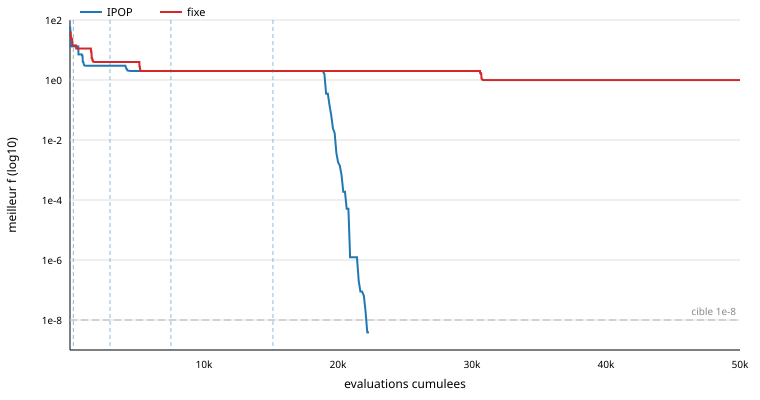

In [7]:
// Figure : log10(meilleur f) en fonction des evaluations cumulees, run median de chaque
// strategie sur Rastrigin ; traits verticaux aux redemarrages IPOP, detectes comme les
// points ou le delta d'evals entre generations double (la population double) ; ligne
// grise horizontale a la cible 1e-8 du protocole.
record FigCurve2(string Label, List<(int Evals, double Best)> Trace, IReadOnlyList<int> Sizes, string Color);
// Le noyau est en culture francaise : "70,1" serait lu par SVG comme deux coordonnees
// (70 et 1). Tous les attributs de geometrie passent donc par InvariantCulture.
static string FN(double v) => v.ToString("0.##", System.Globalization.CultureInfo.InvariantCulture);
var curves2 = new List<FigCurve2>();
foreach (var strat in new[] { "IPOP", "fixe" })
{
    var runs = results[$"Rastrigin d=5|{strat}"];
    var med = runs.OrderBy(r => r.Best).ElementAt(runs.Count / 2);
    curves2.Add(new FigCurve2(strat, med.Trace, med.Sizes, strat == "IPOP" ? "#1f77b4" : "#d62728"));
}
var sb2 = new StringBuilder();
sb2.AppendLine("<svg xmlns=\"http://www.w3.org/2000/svg\" width=\"760\" height=\"400\" viewBox=\"0 0 760 400\" font-family=\"sans-serif\" font-size=\"12\">");
sb2.AppendLine("<rect width=\"760\" height=\"400\" fill=\"white\"/>");
int ml = 70, mr = 20, mt = 20, mb = 50;
double w = 760 - ml - mr, h = 400 - mt - mb;
var allPts2 = curves2.SelectMany(c => c.Trace).ToList();
double maxE = allPts2.Max(p => p.Evals), minLog = -9, maxLog = 2.0;
double GX(double e) => ml + w * e / maxE;
double GY(double lv) => mt + h * (1 - (lv - minLog) / (maxLog - minLog));
sb2.AppendLine($"<line x1=\"{ml}\" y1=\"{mt}\" x2=\"{ml}\" y2=\"{FN(mt + h)}\" stroke=\"black\"/>");
sb2.AppendLine($"<line x1=\"{ml}\" y1=\"{FN(mt + h)}\" x2=\"{FN(ml + w)}\" y2=\"{FN(mt + h)}\" stroke=\"black\"/>");
// La cible du protocole : l'axe descend une decade en dessous pour laisser voir la plongee.
sb2.AppendLine($"<line x1=\"{ml}\" y1=\"{FN(GY(-8))}\" x2=\"{FN(ml + w)}\" y2=\"{FN(GY(-8))}\" stroke=\"#888888\" stroke-dasharray=\"7 4\"/>");
sb2.AppendLine($"<text x=\"{FN(ml + w - 4)}\" y=\"{FN(GY(-8) - 5)}\" text-anchor=\"end\" font-size=\"10\" fill=\"#888888\">cible 1e-8</text>");
for (int lv = -8; lv <= 2; lv += 2)
    sb2.AppendLine($"<line x1=\"{ml}\" y1=\"{FN(GY(lv))}\" x2=\"{FN(ml + w)}\" y2=\"{FN(GY(lv))}\" stroke=\"#e0e0e0\"/><text x=\"{ml - 8}\" y=\"{FN(GY(lv) + 4)}\" text-anchor=\"end\" font-size=\"10\">1e{lv}</text>");
foreach (int e in new[] { 10000, 20000, 30000, 40000, 50000 })
    sb2.AppendLine($"<text x=\"{FN(GX(e))}\" y=\"{mt + h + 18}\" text-anchor=\"middle\" font-size=\"10\">{e / 1000}k</text>");
sb2.AppendLine($"<text x=\"{FN(ml + w / 2)}\" y=\"{mt + h + 38}\" text-anchor=\"middle\">evaluations cumulees</text>");
sb2.AppendLine($"<text x=\"16\" y=\"{FN(mt + h / 2)}\" transform=\"rotate(-90 16 {FN(mt + h / 2)})\" text-anchor=\"middle\">meilleur f (log10)</text>");
foreach (var curve in curves2)
{
    // La courbe s'arrete au bord bas de l'axe (1e-9) : franchir la cible se lit comme
    // une sortie du cadre sans ecraser l'echelle des generations utiles.
    var pts = curve.Trace.Where(p => p.Best > 0 && Math.Log10(p.Best) >= minLog)
                         .Select(p => (GX(p.Evals), GY(Math.Log10(p.Best)))).ToList();
    if (pts.Count < 2) continue;
    var path = new StringBuilder("M ");
    foreach (var (px, py) in pts) path.Append($"{FN(px)} {FN(py)} L ");
    sb2.AppendLine($"<path d=\"{path.ToString(0, path.Length - 2)}\" fill=\"none\" stroke=\"{curve.Color}\" stroke-width=\"2\"/>");
}
// Traits verticaux : au sein d'un run chaque generation coute exactement lambda evals,
// donc le delta entre points consecutifs de la trace double au restart IPOP.
var ipopTrace2 = curves2[0].Trace;
var restarts2 = new List<double>();
for (int i = 2; i < ipopTrace2.Count; i++)
{
    int d1 = ipopTrace2[i].Evals - ipopTrace2[i - 1].Evals;
    int d0 = ipopTrace2[i - 1].Evals - ipopTrace2[i - 2].Evals;
    if (d0 > 0 && d1 == 2 * d0) restarts2.Add(ipopTrace2[i - 1].Evals);
}
foreach (double r in restarts2)
    sb2.AppendLine($"<line x1=\"{FN(GX(r))}\" y1=\"{mt}\" x2=\"{FN(GX(r))}\" y2=\"{FN(mt + h)}\" stroke=\"#1f77b4\" stroke-dasharray=\"4 3\" opacity=\"0.5\"/>");
float lx = ml + 10;
foreach (var curve in curves2)
{
    sb2.AppendLine($"<line x1=\"{FN(lx)}\" y1=\"{mt - 8}\" x2=\"{FN(lx + 22)}\" y2=\"{mt - 8}\" stroke=\"{curve.Color}\" stroke-width=\"2\"/><text x=\"{FN(lx + 27)}\" y=\"{mt - 4}\" font-size=\"11\">{curve.Label}</text>");
    lx += 80;
}
sb2.AppendLine("</svg>");
// Fournee portabilite SVG (#26783, mecanisme #28029) : sb2 est un SVG pur, emis en
// image/svg+xml (forme canonique Jupyter) et non sur stdout, ou le lecteur verrait
// le balisage brut au lieu de la courbe.
sb2.ToString().DisplayAs("image/svg+xml");


### Lecture de la figure

La courbe bleue trace le meilleur $f$ **cumulé** — le contrôleur garde le meilleur de toutes les exécutions, la courbe ne remonte donc jamais : ce sont les **paliers** qui racontent les restarts, pas des dents de scie. Chaque trait vertical pointillé marque un doublement (la colonne `tailles` du banc donne la suite $8 \to 16 \to 32 \to 64 \to 128$ sur le run médian) : à chaque stagnation, la recherche repart d'une covariance identité mais avec une population doublée — plus **globale** — et la descente reprend plus profonde. La cible 1e-8 (ligne grise) est franchie vers 22 000 évaluations, dans la cinquième exécution (taille 128). La courbe rouge n'a pas ce levier : même budget, 53 exécutions de population 8, elle rampe de ~60 jusqu'à ~1,0 — un minimum local de Rastrigin (la valeur 0,995 du banc) — et épuise le budget sans jamais approcher la cible. Le doublement n'accélère pas la convergence : il achète l'**échelle de la recherche**.

## Le négatif honnête : Sphere

Sur un unimodal, le papier mesure « performance is similar » — aucun restart n'a de raison d'aider, la première exécution converge droit. C'est le contrôle de sanité du **verdict**, pas de l'algorithme : si l'IPOP « gagnait » aussi sur Sphere, quelque chose serait faux dans le protocole (le doublement ne peut aider que là où il faut explorer ailleurs).


In [8]:
// Le controle Sphere : les deux strategies cote a cote, tailles et evals rendues.
foreach (var strat in new[] { "IPOP", "fixe" })
{
    var runs = results[$"Sphere d=5|{strat}"];
    foreach (var (r, i) in runs.Select((r, i) => (r, i)))
        Console.WriteLine($"Sphere {strat,-4} graine {Seeds[i]} : {r.Evals,6} evals, meilleur f = {r.Best:E3}, cible a {(r.ReachedAt > 0 ? r.ReachedAt.ToString() : "jamais")}, tailles [{string.Join(",", r.Sizes)}]");
}


Sphere IPOP graine 4242 :   3200 evals, meilleur f = 2,529E-037, cible a 862, tailles [8]


Sphere IPOP graine 1717 :   3200 evals, meilleur f = 7,738E-043, cible a 741, tailles [8]


Sphere IPOP graine 2718 :   3200 evals, meilleur f = 6,853E-041, cible a 659, tailles [8]


Sphere fixe graine 4242 :   3200 evals, meilleur f = 2,529E-037, cible a 862, tailles [8]


Sphere fixe graine 1717 :   3200 evals, meilleur f = 7,738E-043, cible a 741, tailles [8]


Sphere fixe graine 2718 :   3200 evals, meilleur f = 6,853E-041, cible a 659, tailles [8]


### Lecture du contrôle Sphere

Verdict mesuré : **identique au bit près**. Les six lignes se répondent deux à deux — même budget de 3 200 évaluations, mêmes meilleurs $f$ par graine (2,5e-37, 7,7e-43, 6,9e-41), même colonne `tailles [8]` : **aucun restart n'a jamais été déclenché**. La première exécution atteint la cible en 659 à 862 évaluations, le doublement ne s'est jamais invité. C'est le « performance is similar » du papier sur les unimodales, à l'échelle du carnet : là où il n'y a qu'un bassin, repartir ailleurs ne peut rien acheter. Le contrôle valide le protocole — si l'IPOP avait « gagné » ici aussi, le verdict Rastrigin aurait été suspect.

### Exercice 1 : partir petit — l'effet de $\lambda_0$

Le papier démarre petit ($\lambda(5) = 8$) pour que les premiers restarts soient **rapides et locaux**, et que la population ne devienne globale que si nécessaire. Mesurer ce que change un $\lambda_0$ plus grand (16, 32) sur Rastrigin à budget égal : les premières exécutions consomment-elles plus d'évaluations pour la même information ? Le verdict final bouge-t-il ?


In [9]:
// Exercice 1 : effet de lambda0 sur Rastrigin, budget egal.
// Squelette d'accompagnement — le run reste a faire par l'etudiant.
foreach (int l0 in new[] { 16, 32 })
{
    // var outcome = RunIpop(Rastrigin, -5.12, 5.12, 4242, lambda0: l0, maxRestarts: 12, budget: 50_000);
    // Console.WriteLine($"lambda0={l0} : ...");
}
Console.WriteLine("Exercice a completer : comparer les tailles executees et les evals jusqu'a la cible pour lambda0 = 8 (banc), 16, 32.");


Exercice a completer : comparer les tailles executees et les evals jusqu'a la cible pour lambda0 = 8 (banc), 16, 32.


### Exercice 2 : la garde de budget, côté appelant

Le contrat du contrôleur laisse le budget global à la charge de l'appelant — c'est le complément déclaré ouvert de l'API. Le harnais `RunIpop` du carnet porte une garde simple (`totalEvals >= budget` teste à chaque retour de callback). L'écrire soi-même en variant la **granularité** : une garde par **génération** (via `Termination` ou un compteur dans le `FuncFitness`) au lieu d'une garde par exécution — que se passe-t-il lorsqu'une exécution de population 128 démarre alors qu'il ne reste que 300 évaluations ?


In [10]:
// Exercice 2 : garde de budget par generation au lieu de par execution.
// Squelette d'accompagnement — la garde reste a ecrire par l'etudiant.
// Indice : OneRun rend la main a GenerationNumberTermination ; une garde fine doit
// couper AVANT que l'execution ne depasse le budget restant.
Console.WriteLine("Exercice a completer : mesurer le depassement effectif du budget avec la garde par execution, puis l'annuler avec une garde par generation.");


Exercice a completer : mesurer le depassement effectif du budget avec la garde par execution, puis l'annuler avec une garde par generation.


### Exercice 3 : BIPOP à la main

Le successeur de l'IPOP (Hansen, 2008-2009) **alterne** : un restart à population doublée, un restart à population de base avec pas réinitialisé — les deux régimes se nourrissent l'un l'autre à budget partagé. Le contrôleur ne sait faire que doubler. Écrire la boucle BIPOP côté appelant, à la main, sur le même canevas — et mesurer si l'alternance bat le doublement systématique sur Rastrigin à budget égal.


In [11]:
// Exercice 3 : BIPOP cote appelant — alterner population doublee et population de base.
// Squelette d'accompagnement — la boucle reste a ecrire par l'etudiant.
// Indice : la boucle du RunFixed montre le canevas d'un restart isole ; il faut alterner
// les tailles (l0 * 2^k et l0) et partager le budget entre les deux regimes.
Console.WriteLine("Exercice a completer : comparer IPOP (doublement systematique) et BIPOP (alternance) sur Rastrigin, budget 50 000.");


Exercice a completer : comparer IPOP (doublement systematique) et BIPOP (alternance) sur Rastrigin, budget 50 000.


## Liens

- MGS-07e CMA-ES — le composé CMA-ES à population fixe : rang-un, CSA, restart-on-stall, et l'exercice qui annonçait ce carnet
- [MGS-07d MichalewiczDixonPrice](MGS-07d-MichalewiczDixonPrice.ipynb) — les paysages 5-D en projection MAX
- [Search-05b NES en C#](../Part1-Foundations/Search-05b-NaturalEvolutionStrategies-CSharp.ipynb) — le rang-μ par gradient naturel
- [MGS-08 LandscapeExplorer](MGS-08-LandscapeExplorer.ipynb) — voir les paysages que l'IPOP parcourt


## À retenir

1. **À budget égal (50 000 évaluations), le doublement achète le paysage où il faut chercher ailleurs** : sur Rastrigin d=5, l'IPOP atteint la cible 1e-8 sur 3 graines sur 3 (~22 000 évaluations médianes, tailles doublées 8→128 en 4 restarts) quand la population fixe n'y arrive qu'une fois sur trois (meilleur médian 0,995, budget épuisé) ; sur Ackley comme sur Sphere, les deux régimes atteignent la cible sans que le doublement joue (Ackley : `[8]` côté IPOP contre `[8,8]` côté fixe, deux runs à population constante pour le même budget ; Sphere : `[8]` des deux côtés) — seul Rastrigin discrimine.
2. **Le contrôle unimodal tient** : sur Sphere, IPOP et fixe sont identiques au bit près par graine (3 200 évaluations, cible atteinte en 659 à 862, aucun restart) — le « performance is similar » d'Auger & Hansen sur les unimodales, reproduit à l'échelle du carnet.
3. **L'orchestration et l'exécution sont séparés** : `IpopRestartController` ne connaît ni le GA ni la fitness — le budget global vit chez l'appelant, et c'est ce vide que l'exercice 2 fait remplir.

## Vérifiez votre compréhension

1. Pourquoi le redémarrage local peut-il battre l'IPOP sur certains paysages (le papier en compte 4 sur 60) ? Quel ingrédient du paysage rend le doublement coûteux sans bénéfice ?
2. La trace `PopulationSizes` rendue par le contrôleur : pourquoi est-elle une **liste** et non un simple compteur de restarts ?
3. Si le budget est épuisé au milieu d'une exécution de population 128, que rend le contrôleur — et pourquoi la garde de l'exercice 2 reste-t-elle nécessaire malgré `maxRestarts` ?


## Pour aller plus loin

- **Auger & Hansen 2005**, *A Restart CMA Evolution Strategy With Increasing Population Size* (CEC 2005, pp. 1769-1776) — le protocole budget-égal et la suite CEC 2005 complète.
- **Hansen 2023**, *The CMA Evolution Strategy: A Tutorial* — section restarts : les critères de stagnation qui déclenchent chaque exécution.
- **Carnet suivant** : [MGS-08 LandscapeExplorer](MGS-08-LandscapeExplorer.ipynb) — le paysage que ces populations parcourent, rendu visible.
